<a href="https://colab.research.google.com/github/CPTR295/Learning-Langchain/blob/main/BasicProjects.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install langchain_openai

In [2]:
from google.colab import userdata
api_key = userdata.get("OPENROUTER_API_KEY")

In [9]:
from typing import Annotated,TypedDict
from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage

model = ChatOpenAI( #Many providers provide same api interface as openai including openrouter
    model="nvidia/nemotron-3-ultra-550b-a55b:free",
    api_key=api_key,
    base_url="https://openrouter.ai/api/v1"
)
class State(TypedDict):
    # Messages have the type "list". The `add_messages`
    # function in the annotation defines how this state should
    # be updated (in this case, it appends new messages to the
    # list, rather than replacing the previous messages)
    messages: Annotated[list, add_messages]


def chatbot(state: State):
    answer = model.invoke(state["messages"])
    return {"messages": [answer]}


builder = StateGraph(State)

builder.add_node("chatbot", chatbot)

builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", END)

graph = builder.compile()

# Example usage

input = {"messages": [HumanMessage("hi!")]}
for chunk in graph.stream(input):
    print(chunk)

{'chatbot': {'messages': [AIMessage(content='Hi there! How can I help you today? 😊', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 39, 'prompt_tokens': 18, 'total_tokens': 57, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': 0, 'reasoning_tokens': 29, 'rejected_prediction_tokens': None, 'image_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'video_tokens': 0}, 'cost': 0, 'is_byok': False, 'cost_details': {'upstream_inference_cost': 0, 'upstream_inference_prompt_cost': 0, 'upstream_inference_completions_cost': 0}}, 'model_provider': 'openai', 'model_name': 'nvidia/nemotron-3-ultra-550b-a55b:free', 'system_fingerprint': None, 'id': 'gen-1793254974-JDMsHQk751Tg1CvQJpBi', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a18653-6526-70a7-b7cd-41b992bb4510-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 18, 'output_tokens': 

In [12]:
from typing import Annotated,TypedDict
from langchain_core.messages import HumanMessage,SystemMessage
from langchain_openai import ChatOpenAI
from langgraph.graph import START,END,StateGraph
from langgraph.graph.message import add_messages

model_low_temp = ChatOpenAI( #Many providers provide same api interface as openai including openrouter
    model="nvidia/nemotron-3-ultra-550b-a55b:free",
    api_key=api_key,
    base_url="https://openrouter.ai/api/v1",
    temperature=0.1
)

model_high_temp = ChatOpenAI(
    model="nvidia/nemotron-3-ultra-550b-a55b:free",
    api_key=api_key,
    base_url="https://openrouter.ai/api/v1",
    temperature=0.9
)

class State(TypedDict):
  messages: Annotated[list,add_messages]
  user_query: str
  sql_query: str
  sql_explanation: str

  class Input(TypedDict):
    user_query: str

  class Output(TypedDict):
    sql_query: str
    sql_explanation: str

  generate_prompt = SystemMessage(
      "You are a helpful data analyst, who generates SQL queries for users based on their questions."
  )

  def generate_sql(state:State)->State:
    user_message = HumanMessage(state['user_query'])
    messages = [generate_prompt,*state['messages'],user_message]
    res = model_low_temp.invoke(messages)
    return {
        "sql_query":res.content,
        "messages":[user_message,res]
    }

  explain_prompt = SystemMessage(
      "You are a helpful data analyst, who explains SQL queries for users."
  )

  def explain_sql(state:State)->State:
    messages = [
        explain_prompt,
        *state['messages']
    ]
    res = model_high_temp.invoke(messages)
    return {
        "sql_explanation":res.content,
        "messages":res
    }

  builder = StateGraph(State,input=Input,output=Output)
  builder.add_node("generate_sql",generate_sql)
  builder.add_node("explain_sql",explain_sql)
  builder.add_edge(START,"generate_sql")
  builder.add_edge("generate_sql","explain_sql")
  builder.add_edge("explain_sql",END)
  graph = builder.compile()

  result = graph.invoke({"user_query":"What is the total sales for each product?"})
  print(result)

/tmp/ipykernel_1241/669991585.py:62: LangGraphDeprecatedSinceV05: `input` is deprecated and will be removed. Please use `input_schema` instead. Deprecated in LangGraph V0.5 to be removed in V2.0.
  builder = StateGraph(State,input=Input,output=Output)
/tmp/ipykernel_1241/669991585.py:62: LangGraphDeprecatedSinceV05: `output` is deprecated and will be removed. Please use `output_schema` instead. Deprecated in LangGraph V0.5 to be removed in V2.0.
  builder = StateGraph(State,input=Input,output=Output)


{'sql_query': "Since you didn't provide a specific database schema, I'll assume a common e-commerce structure with **`products`**, **`orders`**, and **`order_items`** tables.\n\n### Assumed Schema\n*   **`products`**: `product_id`, `product_name`\n*   **`order_items`**: `order_id`, `product_id`, `quantity`, `unit_price` (price at time of sale)\n\n### SQL Query\n\n```sql\nSELECT \n    p.product_id,\n    p.product_name,\n    SUM(oi.quantity * oi.unit_price) AS total_sales\nFROM \n    products p\nJOIN \n    order_items oi ON p.product_id = oi.product_id\nGROUP BY \n    p.product_id, \n    p.product_name\nORDER BY \n    total_sales DESC;\n```\n\n---\n\n### How this works:\n1.  **`JOIN`**: Connects products to their sales records in `order_items`.\n2.  **`quantity * unit_price`**: Calculates the revenue for each specific line item (handles quantity > 1).\n3.  **`SUM(...)`**: Aggregates the revenue across all orders for that product.\n4.  **`GROUP BY`**: Ensures we get one row per product.\n

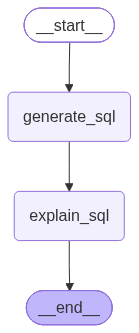

In [13]:
graph